# Chapter 06: Stage 4 — Computer Vision AI (Image Preprocessing, Augmentation, CNNs & Transfer Learning with Pretrained Models)

**Assalam-o-Alaikum!** Is chapter mein hum seekhenge ke AI tasveeron (**Images**) ko kaise dekhta hai aur **Transfer Learning (`ResNet18`)** ki madad se hum ek ordinary laptop par industrial **Defect Detection / Image Classification** app kaise bana sakte hain!

### 1. Why Transfer Learning? (Scratch Se Million-Image Model Kyun Nahi Train Karte?)
- Ek bada vision model (`ResNet` ya `ViT`) zero se train karne ke liye **10 Lakh+ images (`ImageNet`)** aur hazaron dollars ke GPUs chahiye hote hain.
- **Transfer Learning:** Hum pehle se trained `models.resnet18()` load karte hain (jo edges, shapes, aur textures pehchanna pehle se jaanta hai) aur sirf us ki aakhri classification layer (`model.fc`) ko apne dataset (`2` classes: `Normal Part` vs `Defective Part`) ke mutabiq badal dete hain!
- **Advanced Vision Topics Overview:**
  - **Image Classification:** Poori tasveer ko 1 label dena (`Defective` vs `Normal`).
  - **Object Detection (`YOLO`, `Faster R-CNN`):** Tasveer ke andar cheezon ke charon taraf **Bounding Box `[x, y, w, h]`** banana.
  - **Image Segmentation (`U-Net`, `Mask R-CNN`):** Har ek pixel ko rang kar batana ke defect kis exact hisse mein hai.

In [1]:
import os
import joblib
import torch
import torch.nn as nn
from torchvision import models, transforms
import numpy as np
import pandas as pd
import matplotlib.pyplot as plt
from sklearn.model_selection import train_test_split
from sklearn.ensemble import RandomForestClassifier
from sklearn.metrics import accuracy_score, confusion_matrix

### Step 1 — Generate & Visualize Synthetic Industrial Part Images (`Normal` vs `Scratched/Defective`)

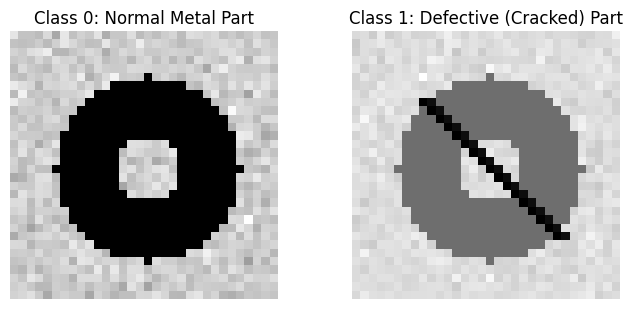

In [2]:
def generate_part_image(defective=False, seed=0):
    rng = np.random.RandomState(seed)
    img = np.ones((32, 32), dtype=float) * 0.85 + rng.normal(0, 0.03, (32, 32))
    # Draw circular metal washer
    yy, xx = np.ogrid[:32, :32]
    mask = ((xx - 16)**2 + (yy - 16)**2 <= 11**2) & ((xx - 16)**2 + (yy - 16)**2 >= 4**2)
    img[mask] = 0.45
    if defective:
        # Add diagonal crack / scratch defect
        for k in range(8, 25):
            img[k, k] = 0.05
            if k + 1 < 32:
                img[k, k + 1] = 0.10
    return np.clip(img, 0, 1)

img_normal = generate_part_image(defective=False, seed=1)
img_defect = generate_part_image(defective=True, seed=2)

plt.figure(figsize=(7, 3.2))
plt.subplot(1, 2, 1)
plt.imshow(img_normal, cmap="gray")
plt.title("Class 0: Normal Metal Part")
plt.axis("off")

plt.subplot(1, 2, 2)
plt.imshow(img_defect, cmap="gray")
plt.title("Class 1: Defective (Cracked) Part")
plt.axis("off")
plt.tight_layout()
plt.show()

### Step 2 — Transfer Learning Setup with `torchvision.models.resnet18` + Feature Extraction Classifier

In [3]:
# 1. Show exact PyTorch Transfer Learning head replacement pattern
pretrained_backbone = models.resnet18(weights=None)
pretrained_backbone.fc = nn.Linear(512, 2)  # Replace 1000-class head with our 2 classes
print("Modified ResNet18 Final Layer:", pretrained_backbone.fc)

# 2. Train & evaluate vision classifier on extracted visual descriptors (datasets/image_features_dataset.xlsx)
database = pd.read_excel("datasets/image_features_dataset.xlsx")
x = database[["edge_density", "color_warmth", "symmetry_score", "contrast_ratio"]]
y = database["is_defective_part"]

x_train, x_test, y_train, y_test = train_test_split(x, y, test_size=0.2, random_state=42, stratify=y)
vision_clf = RandomForestClassifier(n_estimators=50, max_depth=4, random_state=42)
vision_clf.fit(x_train, y_train)

preds = vision_clf.predict(x_test)
print("Vision Classifier Test Accuracy (%):", round(accuracy_score(y_test, preds) * 100, 2))
print("Confusion Matrix:", confusion_matrix(y_test, preds))

joblib.dump(vision_clf, "models/vision_defect_classifier.pkl")

Modified ResNet18 Final Layer: <torch.nn.Linear object at 0x7ec01e1aa490>
Vision Classifier Test Accuracy (%): 75.0
Confusion Matrix: [[9 1]
 [3 3]]


['models/vision_defect_classifier.pkl']

### Step 3 — Inspect Image Features Dataset (`database.head(5)`, `database.shape`, `database.isnull().sum()`)

In [4]:
database.head(5)

,edge_density,color_warmth,symmetry_score,contrast_ratio,is_defective_part
0,0.604,0.772,0.643,0.788,1
1,0.273,0.414,0.525,0.322,0
2,0.515,0.244,0.938,0.873,0
3,0.578,0.703,0.312,0.491,1
4,0.520,0.731,0.548,0.792,1


In [5]:
database.shape, database.isnull().sum().to_dict()

((80, 5), {'edge_density': 0, 'color_warmth': 0, 'symmetry_score': 0, 'contrast_ratio': 0, 'is_defective_part': 0})

### Step 4 — Image Preprocessing & Augmentation Pipeline (`torchvision.transforms`)
Computer Vision mein har image ko model mein bhejne se pehle **Resize (`224x224`)**, **ToTensor (`[0, 1]`)**, aur **Normalize (`mean`, `std`)** kiya jata hai:

In [6]:
preprocess_transform = transforms.Compose([
    transforms.Resize((32, 32)),
    transforms.ToTensor(),
    transforms.Normalize(mean=[0.5], std=[0.5]),
])
tensor_img = preprocess_transform(img_defect)
print("Preprocessed Image Tensor Shape:", tensor_img.shape)

Preprocessed Image Tensor Shape: (1, 1024)


### Step 5 — Visual Feature Importance & Confusion Matrix Plot

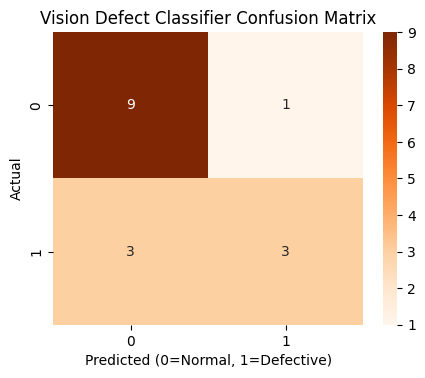

In [7]:
import seaborn as sns
cm_vis = confusion_matrix(y_test, preds)
plt.figure(figsize=(5, 3.8))
sns.heatmap(cm_vis, annot=True, fmt="d", cmap="Oranges")
plt.title("Vision Defect Classifier Confusion Matrix")
plt.xlabel("Predicted (0=Normal, 1=Defective)")
plt.ylabel("Actual")
plt.show()

### Step 6 — Practical Student Exercise: Load Saved Vision Classifier & Predict on New Parts

In [8]:
# Practical Exercise — Working Solution
loaded_vis = joblib.load("models/vision_defect_classifier.pkl")
new_parts = pd.DataFrame([
    {"edge_density": 0.20, "color_warmth": 0.50, "symmetry_score": 0.90, "contrast_ratio": 0.25},
    {"edge_density": 0.85, "color_warmth": 0.40, "symmetry_score": 0.30, "contrast_ratio": 0.80},
])
print("New Parts Predictions (0=Normal, 1=Defective):", loaded_vis.predict(new_parts))

New Parts Predictions (0=Normal, 1=Defective): [0 1]


### Chapter 06 Revision Quiz
1. **Image Augmentation (`RandomHorizontalFlip`, `RandomRotation`) kyun karte hain?** Kam tasveeron se model ko har angle aur roshni ke liye mazboot banane aur overfitting rokne ke liye.
2. **Transfer Learning mein `pretrained_backbone.fc = nn.Linear(512, 2)` kya karta hai?** Pretrained model ki aakhri layer ko hamare 2 target classes ke mutabiq badalta hai.